## AC Project

## 1. Data Exploration

The following work we will analyse a dataset of Diabetes Risk, which includes 17 features with information related to their lifestyle and blood samples.

In [1]:
import pandas as pd

data = pd.read_csv('diabetes_risk.csv', usecols=['age', 'gender', 'bmi', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'diabetes_risk'])

print(data)

       age  gender   bmi family_history_diabetes physical_activity_level  \
0       47  Female  26.5                     Yes               Sedentary   
1       53  Female  20.5                     Yes                Moderate   
2       47    Male  31.3                      No                Moderate   
3       41    Male  22.8                      No               Sedentary   
4       57  Female  16.7                      No               Sedentary   
...    ...     ...   ...                     ...                     ...   
14995   47    Male  37.7                      No               Sedentary   
14996   48  Female  20.6                      No                Moderate   
14997   34  Female  17.9                      No                  Active   
14998   56    Male  20.7                     Yes                  Active   
14999   54    Male  34.5                      No                Moderate   

            diet_type smoking_status alcohol_consumption  \
0          Vegetarian      

### Histogram

Index(['age', 'gender', 'bmi', 'family_history_diabetes',
       'physical_activity_level', 'diet_type', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm'],
      dtype='str')


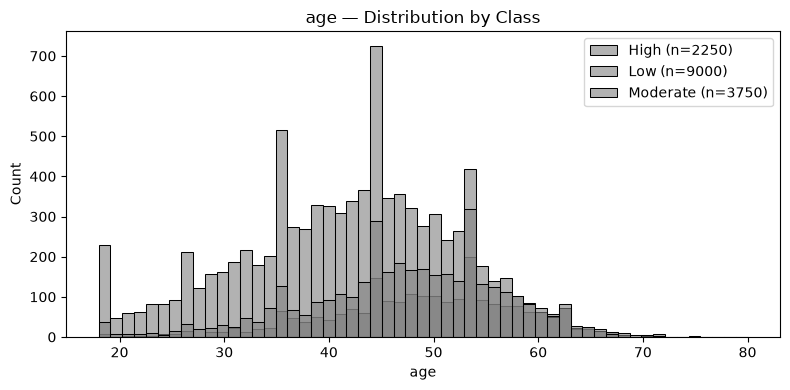

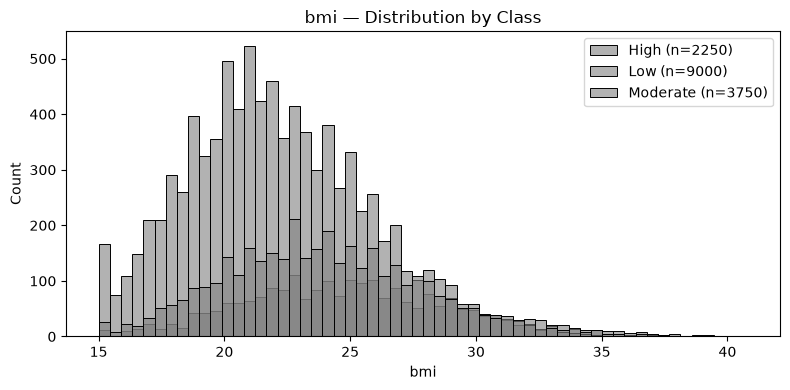

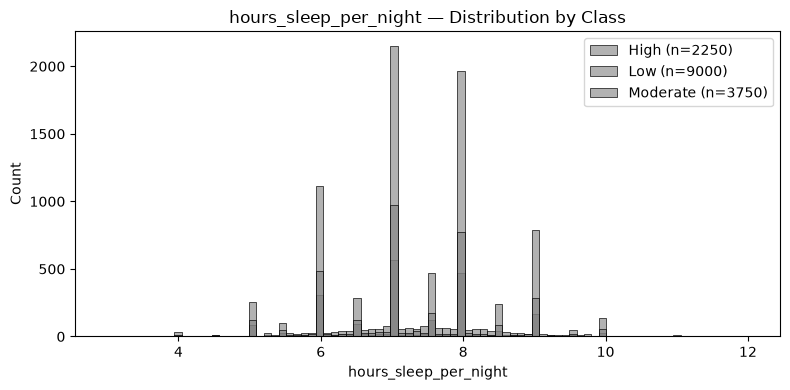

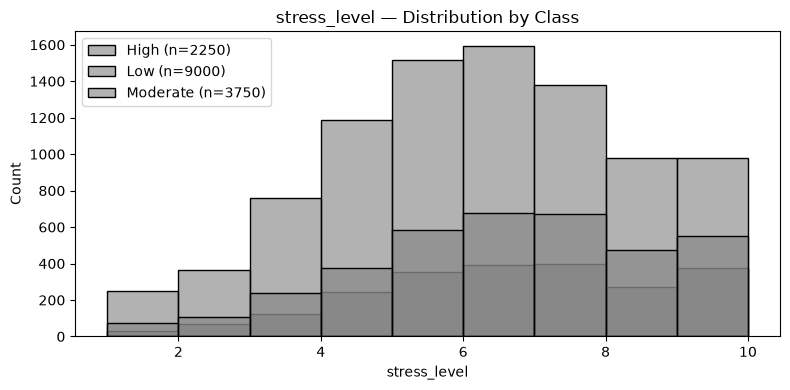

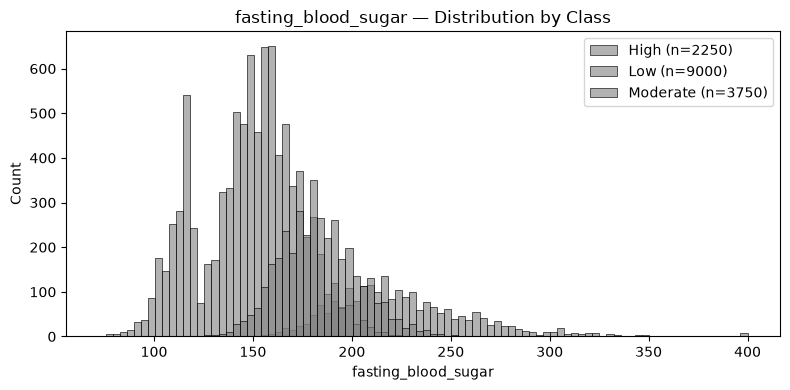

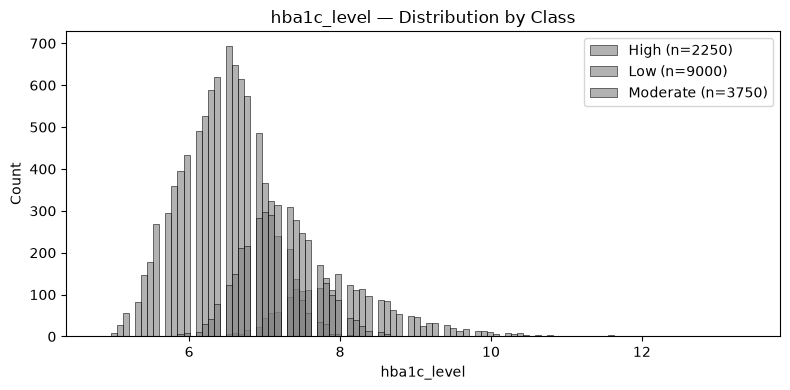

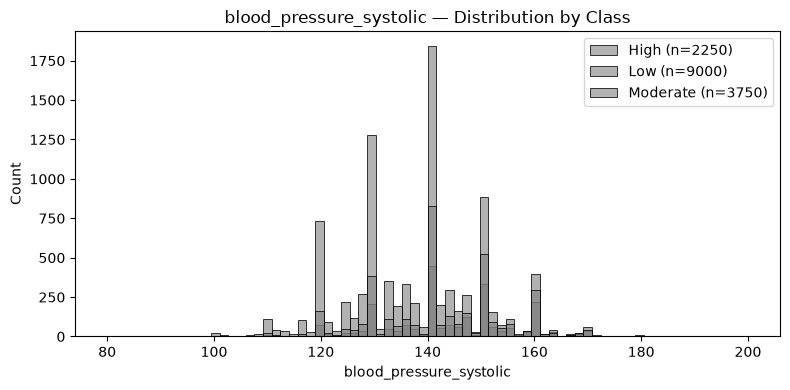

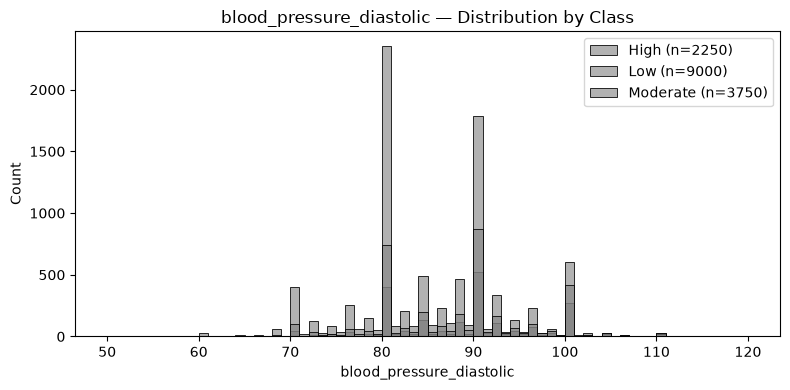

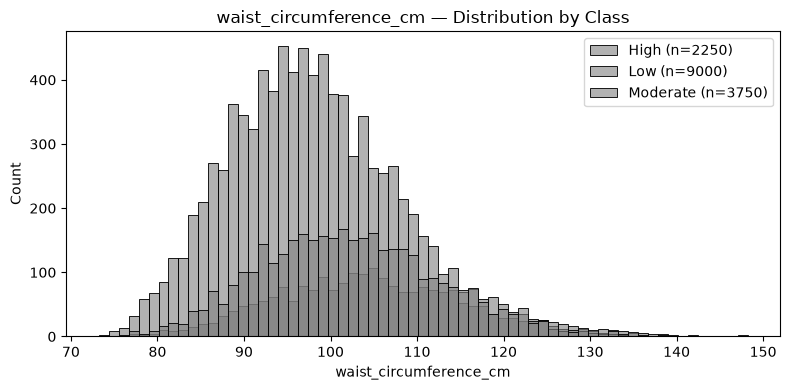

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

target_col = "diabetes_risk"

columns = data.drop(columns=[target_col]).columns

palette = {
    1: "#e76f51",
    2: "#2a9d8f",
    3: "#457b9d"
}

class_labels = {
    1: "Low Risk",
    2: "Moderate Risk",
    3: "High Risk"
}

for col in columns:
    
    if pd.api.types.is_string_dtype(data[col]) or data[col].dtype == "object":
        continue

    plt.figure(figsize=(8, 4))

    bins = np.histogram_bin_edges(data[col].dropna(), bins="auto")

    for cls in sorted(data[target_col].dropna().unique()):
        class_data = data[data[target_col] == cls]

        sns.histplot(
            data=class_data,
            x=col,
            bins=bins,
            label=f"{class_labels.get(cls, cls)} (n={len(class_data)})",
            color=palette.get(cls, "gray"),
            alpha=0.6,
            stat="count",
            edgecolor="black"
        )

    plt.title(f"{col} — Distribution by Class")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Data Cleaning & Partitioning

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

X = data.drop(columns=[target_col])
y = data[target_col]

# Remove rows where either X or y has NaN
mask = ~X.isna().any(axis=1) & ~y.isna()

X_clean = X.loc[mask].reset_index(drop=True)
y_clean = y.loc[mask].reset_index(drop=True)

ids = np.arange(len(X_clean))

id_train, id_temp = train_test_split(
    ids,
    test_size=0.30,
    random_state=42,
    stratify=y_clean
)

id_val, id_test = train_test_split(
    id_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_clean.iloc[id_temp]
)

X_train = X_clean.iloc[id_train]
X_val   = X_clean.iloc[id_val]
X_test  = X_clean.iloc[id_test]

y_train = y_clean.iloc[id_train]
y_val   = y_clean.iloc[id_val]
y_test  = y_clean.iloc[id_test]

print("\nData split:")
print("Training:", len(id_train))
print("Validation:", len(id_val))
print("Test:", len(id_test))

      age gender   bmi family_history_diabetes physical_activity_level  \
4673   60   Male  23.7                      No                Moderate   
3551   44   Male  23.4                      No               Sedentary   
2715   43   Male  20.2                      No                  Active   
4211   37   Male  24.4                      No                  Active   
9874   57   Male  25.8                      No               Sedentary   
...   ...    ...   ...                     ...                     ...   
2518   51   Male  18.7                     Yes                  Active   
4146   67   Male  30.6                      No               Sedentary   
4376   34   Male  19.7                      No                  Active   
8904   24   Male  20.5                     Yes                  Active   
1956   55   Male  23.5                      No               Sedentary   

           diet_type smoking_status alcohol_consumption  \
4673  Non-Vegetarian        Current               Ne